# Does "named" location beat raw coordinates? Three-model comparison

`final.ipynb`'s attribution analysis found `longitude`/`latitude` carry
almost all of the external-data benefit, with every other feature
(zoning, flood, noise, amenities) looking largely redundant with them.
That leaves an open question: is the model actually learning something
about *why* location matters -- or is it just memorizing coordinates as an
opaque lookup key, with no explanation attached?

This notebook adds three new, named location features that stand in for
raw coordinates -- things a person could actually act on, not a latitude
value:

- **`coast_distance_m`** -- distance to the nearest coastline (LINZ NZ
  Coastline polygons, Auckland extent, fetched this session).
- **`cbd_distance_m`** -- distance to the Auckland CBD (fixed reference
  point).
- **`nzdep_score`** -- socioeconomic deprivation (NZDep2023, Stats NZ
  2023 Census, University of Otago, joined via SA2 code).

Three models, same data, same time-based folds:

| Model | Location input | Purpose |
|---|---|---|
| Baseline | None | Shows the value of any location information |
| Named location | Named factors only (new 3 + existing flood/noise/zone/consents/walking-distance) | Explains *why* location matters |
| Augmented | Named factors + coordinates | Best accuracy |

**Headline metric:** how much of the "value of location" gap do the named
factors recover on their own, without coordinates:
`(baseline RMSE - named RMSE) / (baseline RMSE - augmented RMSE)`.

**Caveats, stated up front:**
- NZDep2023 is published at 2023 SA2 boundaries; this project's SA2
  geometry file is the 2025 version. 98.0% of SA2 codes match directly;
  the remaining ~2% (boundary changes between versions) get a missing
  value, median-imputed like any other gap in this pipeline.
- `coast_distance_m` uses the coastline as *land polygon boundaries*, not
  a cleaned "mainland only" line -- distance to the nearest small island
  or harbour inlet counts the same as distance to the open coast. This is
  a reasonable first cut, not a perfect definition of "coast."

## 1. Import data (identical to final.ipynb)

In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 70)

df = pd.read_parquet("./cache/dvrs_with_team_external.parquet")
print(f"Loaded {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head()

Loaded 92,010 rows, 56 columns


,valuation_roll_number,valuation_number_assessment,valuation_number_suffix,sale_date,district_code,sale_type,sales_group,sale_tenure,price_value_relationship,sale_price_gross,sale_price_net,sale_price_chattels,sale_price_other,capital_value,land_value,current_effective_valuation_date,situation_number,additional_situation_number,situation_name,certificate_of_title,land_area,zoning,actual_property_use,units_of_use,off_street_parking,building_age_indicator,building_condition_indicator,building_construction_indicator,building_site_coverage,building_total_floor_area,property_category,legal_description,mass_contour,mass_view,mass_scope_of_view,mass_total_floor_area,mass_deck,mass_workshop_laundry,mass_other_improvements,mass_garage_under_main_roof,mass_garage_freestanding,valuation_id_concat,longitude,latitude,in_flood_plain,in_flood_sensitive_area,dist_to_flood_plain_m,dist_to_flood_sensitive_area_m,unitary_plan_zone,linz_matched,walk_supermarket_network_m,walk_bus_stop_network_m,drive_supermarket_network_m,drive_bus_stop_network_m,noise_category_combination,sa2_new_dwellings_consented_12m
0,1,2501710000,NaN,25022026,14,S,701,1,1,1514000,1499000,15000,0,1400000,1025000,45413,166,NaN,Point Chevalier RD,335510,0,9C,91,1,1,192,GG,WI,80,87,RD192A,"Carport 1 DP 384040, Flat 1 DP 384040,",LV,N,N,87,Y,N,N,0,1,1_2501710000,174.706389,-36.865688,False,False,241.910185,4866.407069,60.0,True,1578.192284,54.442135,535.386978,0.000000,outside_current_overlay,20
1,1,2600010100,NaN,1042025,14,S,701,1,1,1515112,1507112,8000,0,1675000,1500000,44348,7,NaN,Montrose ST,NA118D/908,0.0403,9D,91,1,0,193,AA,WT,120,117,RD193B,Lot 2 DP 189123 403m2,LV,N,N,117,Y,N,N,0,0,1_2600010100,174.708779,-36.869417,False,False,194.452135,4614.989420,8.0,True,309.197383,173.432349,134.495189,155.505174,outside_current_overlay,7
2,1,4300000201,NaN,14022025,14,S,701,1,1,1622800,1609800,13000,0,1650000,1360000,44348,5,NaN,St Michaels AV,NA57C/301,0,9C,91,1,1,198,AA,WT,60,124,RD198B,"Flat 3 DP 103999, Lot 4 DP 7475 652m2",LV,N,N,124,Y,N,N,1,0,1_4300000201,174.702890,-36.861304,False,False,199.900952,4667.722058,60.0,True,1720.397633,68.370379,1122.801352,9.608944,outside_current_overlay,3
3,1,4300110000,NaN,17012025,14,S,701,1,1,2105000,2092000,13000,0,2600000,2325000,44348,35,NaN,St Michaels AV,NA405/218,0.0656,9B,91,1,1,193,AA,WT,120,123,RD193B,Lot 2 DP 15494 656m2,EF,N,N,123,Y,N,N,0,0,1_4300110000,174.700846,-36.862339,False,False,18.820703,4814.776819,18.0,True,1981.946279,329.919025,1502.064675,333.383823,outside_current_overlay,11
4,1,4300270001,NaN,11112025,14,S,701,1,2,1875000,1862000,13000,0,2300000,2025000,45413,66,NaN,St Michaels AV,115395,0.0396,9B,91,1,1,192,AA,WI,137,124,RD192B,Lot 1 DP 328302 396m2,EF,W,M,109,Y,N,N,1,0,1_4300270001,174.698847,-36.863616,False,False,6.764028,4804.594688,18.0,True,2224.730646,465.392323,1606.980701,493.788293,outside_current_overlay,9


### 1.1 Remove leakage columns

- `sale_price_net`, `sale_price_chattels`, `sale_price_other`: these add up
  to the target price, so keeping them would be cheating.
- `capital_value`, `land_value`: the council's own valuation, not a real
  property feature. Keeping it would let the model copy an existing price
  estimate instead of learning from the data.

All five are removed before any analysis.

In [2]:
df = df.drop(columns=[
    "sale_price_net", "sale_price_chattels", "sale_price_other",
    "capital_value", "land_value",
])
print(f"Dropped sale_price_net/chattels/other, capital_value, land_value. {df.shape[1]} columns remain.")

Dropped sale_price_net/chattels/other, capital_value, land_value. 51 columns remain.


## 2. Clean up data types (identical to final.ipynb)

In [3]:
def parse_sale_date(s):
    if pd.isna(s):
        return pd.NaT
    s = str(s)
    year = int(s[-4:])
    month = int(s[-6:-4])
    day = int(s[:-6])
    return pd.Timestamp(year=year, month=month, day=day)


df["sale_date_parsed"] = df["sale_date"].apply(parse_sale_date)
df["current_effective_valuation_date_parsed"] = pd.to_datetime(
    pd.to_numeric(df["current_effective_valuation_date"], errors="coerce"), unit="D", origin="1899-12-30"
)

numeric_cols = [
    "sale_price_gross",
    "land_area", "building_total_floor_area",
    "mass_total_floor_area", "building_site_coverage", "off_street_parking",
    "units_of_use", "mass_garage_under_main_roof", "mass_garage_freestanding",
    "longitude", "latitude",
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Team-external numeric columns are already float/Int64, just need a plain float dtype
external_numeric_cols = [
    "walk_supermarket_network_m", "drive_supermarket_network_m",
    "walk_bus_stop_network_m", "drive_bus_stop_network_m",
    "sa2_new_dwellings_consented_12m",
]
for col in external_numeric_cols:
    df[col] = df[col].astype(float)

# Nullable boolean dtype: rows with no LINZ coordinate match (linz_matched=False)
# have None here, not True/False. Casting to "boolean" (not plain bool/object)
# makes `|` propagate that as NA instead of silently treating it as False.
for col in ["in_flood_plain", "in_flood_sensitive_area"]:
    df[col] = df[col].astype("boolean")

print("sale_date_parsed range:", df["sale_date_parsed"].min().date(), "to", df["sale_date_parsed"].max().date())
df[numeric_cols + external_numeric_cols].describe().T

sale_date_parsed range: 2024-01-01 to 2026-08-21


,count,mean,std,min,25%,50%,75%,max
sale_price_gross,92010.0,2.616173e+06,3.899396e+07,1.000000,755000.000000,1000000.000000,1.450000e+06,1.792507e+09
land_area,92010.0,2.580082e-01,4.050016e+00,0.000000,0.000000,0.028650,6.650000e-02,4.820000e+02
building_total_floor_area,92010.0,2.254900e+02,4.633720e+03,0.000000,86.000000,127.000000,1.850000e+02,3.900000e+05
mass_total_floor_area,92010.0,1.157855e+02,7.865629e+01,0.000000,77.000000,108.000000,1.520000e+02,4.888000e+03
building_site_coverage,92010.0,1.322485e+02,2.103515e+03,0.000000,59.000000,94.000000,1.370000e+02,6.000600e+05
off_street_parking,92010.0,1.570775e+00,7.167405e+00,0.000000,0.000000,1.000000,2.000000e+00,9.800000e+02
units_of_use,92010.0,1.049125e+00,7.697022e-01,0.000000,1.000000,1.000000,1.000000e+00,1.550000e+02
mass_garage_under_main_roof,92010.0,7.599826e-01,9.464774e-01,0.000000,0.000000,0.000000,2.000000e+00,5.600000e+01
mass_garage_freestanding,92010.0,3.416368e-01,6.970015e-01,0.000000,0.000000,0.000000,0.000000e+00,2.000000e+01
longitude,87916.0,1.747796e+02,1.158947e-01,174.234241,174.700457,174.765891,1.748747e+02,1.755077e+02


## 3. Build the three new named-location features

### 3.1 Coast distance and CBD distance

Both computed in NZTM2000 (EPSG:2193, metres), the same CRS used
throughout this project's other distance features.

In [4]:
import os
os.environ["OGR_GEOJSON_MAX_OBJ_SIZE"] = "0"

geocoded = df.dropna(subset=["longitude", "latitude"]).copy()
points = gpd.GeoDataFrame(
    geocoded[[]], geometry=gpd.points_from_xy(geocoded["longitude"], geocoded["latitude"]), crs="EPSG:4326",
).to_crs("EPSG:2193")

# Coast: LINZ NZ Coastline (land polygons) -- distance to the polygon
# BOUNDARY (the actual coastline), not to the polygon itself (every onshore
# point is already inside the landmass polygon, so distance-to-polygon
# would trivially be 0 everywhere).
coast_polygons = gpd.read_file("./hazard_data/nz_coastline_auckland.geojson")
coast_lines = gpd.GeoDataFrame(geometry=gpd.GeoSeries(coast_polygons.geometry.boundary, crs="EPSG:4326")).to_crs("EPSG:2193")
coast_nearest = gpd.sjoin_nearest(points, coast_lines, distance_col="coast_distance_m")
coast_nearest = coast_nearest[~coast_nearest.index.duplicated(keep="first")]
df.loc[geocoded.index, "coast_distance_m"] = coast_nearest["coast_distance_m"]

# CBD: fixed reference point (Queen St / Britomart, central Auckland).
CBD_LON, CBD_LAT = 174.7645, -36.8485
cbd_point = gpd.GeoSeries(gpd.points_from_xy([CBD_LON], [CBD_LAT]), crs="EPSG:4326").to_crs("EPSG:2193").iloc[0]
df.loc[geocoded.index, "cbd_distance_m"] = points.distance(cbd_point).values

print(df[["coast_distance_m", "cbd_distance_m"]].describe())

       coast_distance_m  cbd_distance_m
count      87916.000000    87916.000000
mean        1433.896511    16144.802775
std         1614.269560    11383.956089
min            3.308380       21.603508
25%          410.859678     8223.916965
50%          947.981758    13483.950405
75%         1863.896877    22244.584560
max        16172.500924    96155.886894


### 3.2 Socioeconomic deprivation (NZDep2023, via SA2)

Point-in-polygon join to this project's existing SA2 2025 boundaries (same
file used in the earlier, reverted SA2-linking experiment in `tmp.ipynb`),
then an attribute join to the NZDep2023 SA2 table by SA2 code.

In [5]:
sa2_df = pd.read_csv("SA2/statistical-area-2-2025.csv", encoding="utf-8-sig", dtype=str)
sa2 = gpd.GeoDataFrame(
    sa2_df[["SA22025_V1_00"]].rename(columns={"SA22025_V1_00": "sa2_code"}),
    geometry=gpd.GeoSeries.from_wkt(sa2_df["WKT"]), crs="EPSG:4326",
)

geocoded_wgs84 = gpd.GeoDataFrame(
    geocoded[[]], geometry=gpd.points_from_xy(geocoded["longitude"], geocoded["latitude"]), crs="EPSG:4326",
)
sa2_match = gpd.sjoin(geocoded_wgs84, sa2, how="left", predicate="within")
sa2_match = sa2_match[~sa2_match.index.duplicated(keep="first")]
df.loc[geocoded.index, "sa2_code"] = sa2_match["sa2_code"]

nzdep = pd.read_csv("./hazard_data/nzdep2023_sa2.txt", sep="\t", dtype=str)
nzdep["SA2_average_NZDep2023_score"] = pd.to_numeric(nzdep["SA2_average_NZDep2023_score"], errors="coerce")
nzdep["SA2_average_NZDep2023"] = pd.to_numeric(nzdep["SA2_average_NZDep2023"], errors="coerce")

df = df.merge(
    nzdep[["SA22023_code", "SA2_average_NZDep2023_score", "SA2_average_NZDep2023"]].rename(columns={
        "SA22023_code": "sa2_code", "SA2_average_NZDep2023_score": "nzdep_score", "SA2_average_NZDep2023": "nzdep_decile",
    }),
    on="sa2_code", how="left",
)

match_rate = df["nzdep_score"].notna().sum() / df["sa2_code"].notna().sum()
print(f"SA2 match rate (2025 boundary code found in NZDep2023 2023-boundary table): {match_rate:.1%}")
print(df[["nzdep_score", "nzdep_decile"]].describe())

SA2 match rate (2025 boundary code found in NZDep2023 2023-boundary table): 99.8%
        nzdep_score  nzdep_decile
count  87775.000000  87775.000000
mean     999.961641      5.354828
std       83.643694      2.966623
min      869.000000      1.000000
25%      935.000000      3.000000
50%      972.000000      5.000000
75%     1050.000000      8.000000
max     1284.000000     10.000000


## 4. Filter to clean, genuine sales (identical six filters to final.ipynb)

In [6]:
df_cv = df.copy()
assert "capital_value" not in df_cv.columns and "land_value" not in df_cv.columns, (
    "capital_value / land_value leaked back into df_cv -- they must stay dropped "
    "from the feature set, same as the rest of this notebook"
)
print("Confirmed: capital_value / land_value are not present in df_cv")

before = len(df_cv)
df_cv = df_cv[df_cv["zoning"].astype(str).str[0].isin(["9", "1", "2"])]
print(f"Residential / rural / lifestyle zoning only: {len(df_cv):,} / {before:,} rows kept")

before = len(df_cv)
df_cv = df_cv[df_cv["units_of_use"] == 1]
print(f"Single unit of use only: {len(df_cv):,} / {before:,} rows kept")

before = len(df_cv)
df_cv = df_cv[df_cv["sale_tenure"].astype(str) == "1"]
print(f"Freehold sales only: {len(df_cv):,} / {before:,} rows kept")

before = len(df_cv)
df_cv = df_cv[df_cv["sale_type"] == "S"]
print(f"Single-property sales only: {len(df_cv):,} / {before:,} rows kept")

before = len(df_cv)
df_cv = df_cv[df_cv["price_value_relationship"] == "1"]
print(f"Arm's-length market sales only: {len(df_cv):,} / {before:,} rows kept")

before = len(df_cv)
df_cv = df_cv[df_cv["linz_matched"]]
print(f"LINZ-matched coordinate available: {len(df_cv):,} / {before:,} rows kept")

# Sort chronologically -- required for TimeSeriesSplit below, which assumes
# row order IS time order (it does not sort for you).
df_cv = df_cv.sort_values("sale_date_parsed").reset_index(drop=True)
print(f"\nFinal filtered shape: {df_cv.shape}")
print(f"Date range: {df_cv['sale_date_parsed'].min().date()} to {df_cv['sale_date_parsed'].max().date()}")

Confirmed: capital_value / land_value are not present in df_cv
Residential / rural / lifestyle zoning only: 80,070 / 92,010 rows kept
Single unit of use only: 77,370 / 80,070 rows kept
Freehold sales only: 76,395 / 77,370 rows kept
Single-property sales only: 74,112 / 76,395 rows kept
Arm's-length market sales only: 61,244 / 74,112 rows kept
LINZ-matched coordinate available: 59,798 / 61,244 rows kept

Final filtered shape: (59798, 58)
Date range: 2024-01-01 to 2026-08-18


## 5. Feature engineering and feature sets

In [7]:
df_cv["property_type"] = df_cv["property_category"].str[0]
df_cv["sale_year"] = df_cv["sale_date_parsed"].dt.year
df_cv["sale_month"] = df_cv["sale_date_parsed"].dt.month
df_cv["sale_quarter"] = df_cv["sale_date_parsed"].dt.quarter
df_cv["has_flood_risk"] = df_cv["in_flood_plain"] | df_cv["in_flood_sensitive_area"]
df_cv["in_noise_overlay"] = df_cv["noise_category_combination"] != "outside_current_overlay"
df_cv["unitary_plan_zone"] = df_cv["unitary_plan_zone"].fillna(-1).astype(int).astype(str)

BASELINE_CAT = [
    "zoning", "building_age_indicator", "building_condition_indicator",
    "building_construction_indicator", "mass_contour", "mass_view", "mass_scope_of_view",
    "mass_deck", "mass_workshop_laundry", "mass_other_improvements", "property_type", "actual_property_use",
]
BASELINE_NUM = [
    "land_area", "building_total_floor_area", "mass_total_floor_area", "building_site_coverage",
    "off_street_parking", "mass_garage_under_main_roof", "mass_garage_freestanding",
    "sale_year", "sale_month", "sale_quarter",
]
baseline_cols = BASELINE_CAT + BASELINE_NUM

# "Named" location: everything location-related EXCEPT raw coordinates.
NAMED_CAT = ["unitary_plan_zone", "noise_category_combination"]
NAMED_NUM = [
    "dist_to_flood_plain_m", "dist_to_flood_sensitive_area_m", "sa2_new_dwellings_consented_12m",
    "walk_supermarket_network_m", "walk_bus_stop_network_m",
    "coast_distance_m", "cbd_distance_m", "nzdep_score",
]
NAMED_BOOL = ["in_flood_plain", "in_flood_sensitive_area", "has_flood_risk", "in_noise_overlay"]
named_cols = baseline_cols + NAMED_CAT + NAMED_NUM + NAMED_BOOL

COORD_NUM = ["longitude", "latitude"]
augmented_cols = named_cols + COORD_NUM

all_cat = BASELINE_CAT + NAMED_CAT
all_num = BASELINE_NUM + NAMED_NUM + COORD_NUM
all_bool = NAMED_BOOL

for col in all_cat:
    df_cv[col] = df_cv[col].fillna("Unknown").astype(str)

LOG_COLS = ["land_area", "building_total_floor_area", "mass_total_floor_area",
            "walk_supermarket_network_m", "walk_bus_stop_network_m", "coast_distance_m", "cbd_distance_m"]

print(f"Baseline: {len(baseline_cols)} | Named location: {len(named_cols)} (+{len(named_cols)-len(baseline_cols)}) "
      f"| Augmented: {len(augmented_cols)} (+{len(augmented_cols)-len(named_cols)} coordinates)")

Baseline: 22 | Named location: 36 (+14) | Augmented: 38 (+2 coordinates)


## 6. Train all three models on the same 5 time-based folds

Same `TimeSeriesSplit(n_splits=5)` expanding-window design, same fixed
XGBoost hyperparameters, as `final.ipynb` section 14 -- so this result is
directly comparable to that notebook's ablation.

In [8]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import OrdinalEncoder
from xgboost import XGBRegressor


def rmse(y, yhat):
    return np.sqrt(np.mean((y - yhat) ** 2))


def mae(y, yhat):
    return np.mean(np.abs(y - yhat))


def mape(y, yhat):
    return np.mean(np.abs((y - yhat) / y)) * 100


XGB_PARAMS = dict(n_estimators=500, max_depth=6, learning_rate=0.05,
                   subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1)

kf = TimeSeriesSplit(n_splits=5)
fold_rows = []
oof_rows = []

for fold_i, (train_idx, test_idx) in enumerate(kf.split(df_cv), start=1):
    train_df, test_df = df_cv.iloc[train_idx], df_cv.iloc[test_idx]

    encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    encoder.fit(train_df[all_cat])

    X_train = train_df[augmented_cols].copy()
    X_test = test_df[augmented_cols].copy()
    X_train[all_cat] = encoder.transform(train_df[all_cat])
    X_test[all_cat] = encoder.transform(test_df[all_cat])
    for col in all_bool:
        X_train[col] = X_train[col].astype(int)
        X_test[col] = X_test[col].astype(int)
    X_train, X_test = X_train.astype(float), X_test.astype(float)

    nan_cols = [c for c in all_num if X_train[c].isna().any() or X_test[c].isna().any()]
    medians = X_train[nan_cols].median()
    X_train[nan_cols] = X_train[nan_cols].fillna(medians)
    X_test[nan_cols] = X_test[nan_cols].fillna(medians)

    for col in LOG_COLS:
        X_train[col] = np.log1p(X_train[col])
        X_test[col] = np.log1p(X_test[col])

    y_train, y_test = train_df["sale_price_gross"].values, test_df["sale_price_gross"].values
    p1, p99 = np.quantile(y_train, [0.01, 0.99])
    train_keep = (y_train >= p1) & (y_train <= p99)
    test_keep = (y_test >= p1) & (y_test <= p99)
    X_train_f, y_train_f = X_train[train_keep], y_train[train_keep]
    X_test_f, y_test_f = X_test[test_keep], y_test[test_keep]
    test_idx_f = test_idx[test_keep]

    preds = {}
    for name, cols in [("baseline", baseline_cols), ("named", named_cols), ("augmented", augmented_cols)]:
        m = XGBRegressor(**XGB_PARAMS)
        m.fit(X_train_f[cols], y_train_f)
        preds[name] = m.predict(X_test_f[cols])

    fold_rows.append({
        "fold": fold_i, "n_test": len(y_test_f),
        **{f"{name}_RMSE": rmse(y_test_f, preds[name]) for name in preds},
        **{f"{name}_MAE": mae(y_test_f, preds[name]) for name in preds},
        **{f"{name}_MAPE": mape(y_test_f, preds[name]) for name in preds},
    })
    oof_rows.append(pd.DataFrame({
        "row_id": test_idx_f, "fold": fold_i, "actual": y_test_f,
        "baseline_pred": preds["baseline"], "named_pred": preds["named"], "augmented_pred": preds["augmented"],
    }))
    print(f"Fold {fold_i}/5: baseline RMSE=${fold_rows[-1]['baseline_RMSE']:,.0f}  "
          f"named RMSE=${fold_rows[-1]['named_RMSE']:,.0f}  augmented RMSE=${fold_rows[-1]['augmented_RMSE']:,.0f}")

fold_results = pd.DataFrame(fold_rows)
oof = pd.concat(oof_rows, ignore_index=True)
print(f"\nOut-of-fold rows: {len(oof):,}")

Fold 1/5: baseline RMSE=$342,207  named RMSE=$246,312  augmented RMSE=$233,560


Fold 2/5: baseline RMSE=$321,060  named RMSE=$227,638  augmented RMSE=$212,916


Fold 3/5: baseline RMSE=$318,352  named RMSE=$218,813  augmented RMSE=$203,981


Fold 4/5: baseline RMSE=$306,797  named RMSE=$208,279  augmented RMSE=$192,507


Fold 5/5: baseline RMSE=$297,973  named RMSE=$197,387  augmented RMSE=$183,893

Out-of-fold rows: 48,848


## 7. Headline: how much of the location gain do named factors recover?

In [9]:
baseline_rmse = rmse(oof["actual"], oof["baseline_pred"])
named_rmse = rmse(oof["actual"], oof["named_pred"])
augmented_rmse = rmse(oof["actual"], oof["augmented_pred"])

location_gain_total = baseline_rmse - augmented_rmse
location_gain_named = baseline_rmse - named_rmse
recovery_pct = location_gain_named / location_gain_total

print(f"Baseline RMSE (no location):            ${baseline_rmse:,.0f}")
print(f"Named-location RMSE (no coordinates):   ${named_rmse:,.0f}")
print(f"Augmented RMSE (named + coordinates):   ${augmented_rmse:,.0f}")
print()
print(f"Total value of location (baseline - augmented): ${location_gain_total:,.0f}")
print(f"Value captured by named factors alone (baseline - named): ${location_gain_named:,.0f}")
print()
print(f"==> Named factors recover {recovery_pct:.1%} of the location gain, without using coordinates at all.")

Baseline RMSE (no location):            $317,631
Named-location RMSE (no coordinates):   $220,316
Augmented RMSE (named + coordinates):   $206,086

Total value of location (baseline - augmented): $111,545
Value captured by named factors alone (baseline - named): $97,315

==> Named factors recover 87.2% of the location gain, without using coordinates at all.


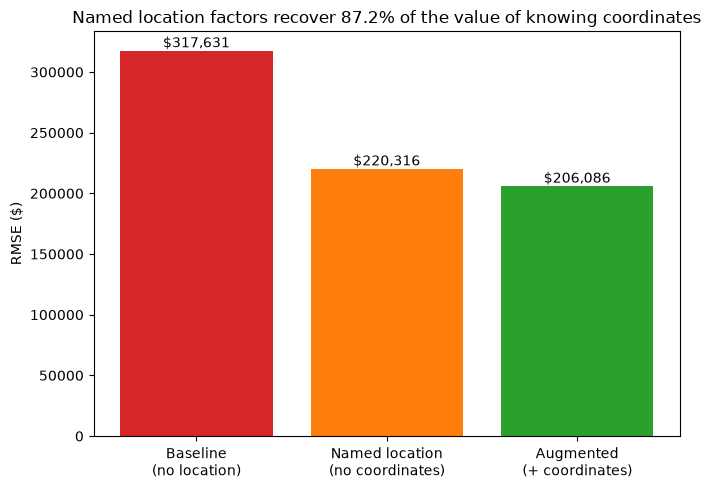

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
labels = ["Baseline\n(no location)", "Named location\n(no coordinates)", "Augmented\n(+ coordinates)"]
vals = [baseline_rmse, named_rmse, augmented_rmse]
colors = ["tab:red", "tab:orange", "tab:green"]
bars = ax.bar(labels, vals, color=colors)
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width() / 2, v, f"${v:,.0f}", ha="center", va="bottom")
ax.set_ylabel("RMSE ($)")
ax.set_title(f"Named location factors recover {recovery_pct:.1%} of the value of knowing coordinates")
plt.tight_layout()
plt.show()

## 8. SHAP for the named-location model, grouped by theme

Refit the named-location model on a single chronological 80/20 split (not
all 5 folds, for speed -- statistical significance was already established
above across all 5 folds), then compute SHAP on a 500-row test sample and
group features into the themes the "named" features were designed around.

In [11]:
import shap

split_point = int(len(df_cv) * 0.8)
train_df, test_df = df_cv.iloc[:split_point], df_cv.iloc[split_point:]

encoder_named = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
encoder_named.fit(train_df[all_cat])

X_train_named = train_df[named_cols].copy()
X_test_named = test_df[named_cols].copy()
X_train_named[all_cat] = encoder_named.transform(train_df[all_cat])
X_test_named[all_cat] = encoder_named.transform(test_df[all_cat])
for col in NAMED_BOOL:
    X_train_named[col] = X_train_named[col].astype(int)
    X_test_named[col] = X_test_named[col].astype(int)
X_train_named, X_test_named = X_train_named.astype(float), X_test_named.astype(float)

nan_cols_named = [c for c in BASELINE_NUM + NAMED_NUM if X_train_named[c].isna().any() or X_test_named[c].isna().any()]
medians_named = X_train_named[nan_cols_named].median()
X_train_named[nan_cols_named] = X_train_named[nan_cols_named].fillna(medians_named)
X_test_named[nan_cols_named] = X_test_named[nan_cols_named].fillna(medians_named)
for col in LOG_COLS:
    X_train_named[col] = np.log1p(X_train_named[col])
    X_test_named[col] = np.log1p(X_test_named[col])

y_train_named = train_df["sale_price_gross"].values
p1n, p99n = np.quantile(y_train_named, [0.01, 0.99])
train_keep_n = (y_train_named >= p1n) & (y_train_named <= p99n)

named_model = XGBRegressor(**XGB_PARAMS)
named_model.fit(X_train_named[train_keep_n], y_train_named[train_keep_n])

shap_sample_named = X_test_named.sample(n=min(500, len(X_test_named)), random_state=42)
explainer_named = shap.TreeExplainer(named_model)
shap_values_named = explainer_named.shap_values(shap_sample_named)

THEMES = {
    "socioeconomic": ["nzdep_score"],
    "coast_and_cbd_access": ["coast_distance_m", "cbd_distance_m"],
    "hazards": ["in_flood_plain", "in_flood_sensitive_area", "has_flood_risk",
                "dist_to_flood_plain_m", "dist_to_flood_sensitive_area_m",
                "noise_category_combination", "in_noise_overlay"],
    "amenities_and_development": ["walk_supermarket_network_m", "walk_bus_stop_network_m",
                                   "sa2_new_dwellings_consented_12m", "unitary_plan_zone"],
}
theme_of = {col: theme for theme, cols in THEMES.items() for col in cols}

mean_abs_shap_named = pd.Series(np.abs(shap_values_named).mean(axis=0), index=named_cols)
theme_share = (
    pd.DataFrame({"feature": named_cols, "mean_abs_shap": mean_abs_shap_named.values,
                  "theme": [theme_of.get(c, "property") for c in named_cols]})
    .groupby("theme")["mean_abs_shap"].sum().sort_values(ascending=False)
)
theme_share_pct = theme_share / theme_share.sum() * 100
print("SHAP importance by theme (named-location model):")
print(theme_share_pct.round(1))

D:\Codes\COMPSCI_760_Group_3_Intelligent_Real_Estate_Price_Prediction_Model\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP importance by theme (named-location model):
theme
property                     60.0
coast_and_cbd_access         22.1
socioeconomic                10.9
amenities_and_development     4.5
hazards                       2.5
Name: mean_abs_shap, dtype: float32


In [12]:
location_theme_detail = pd.DataFrame({
    "feature": named_cols, "mean_abs_shap": mean_abs_shap_named.values,
    "theme": [theme_of.get(c, "property") for c in named_cols],
}).query("theme != 'property'").sort_values("mean_abs_shap", ascending=False)
location_theme_detail

,feature,mean_abs_shap,theme
30,cbd_distance_m,163084.187500,coast_and_cbd_access
31,nzdep_score,90443.656250,socioeconomic
29,coast_distance_m,19293.623047,coast_and_cbd_access
27,walk_supermarket_network_m,18621.123047,amenities_and_development
25,dist_to_flood_sensitive_area_m,12593.922852,hazards
26,sa2_new_dwellings_consented_12m,8216.915039,amenities_and_development
24,dist_to_flood_plain_m,6871.339844,hazards
28,walk_bus_stop_network_m,5480.541992,amenities_and_development
22,unitary_plan_zone,4962.760742,amenities_and_development
32,in_flood_plain,571.761230,hazards


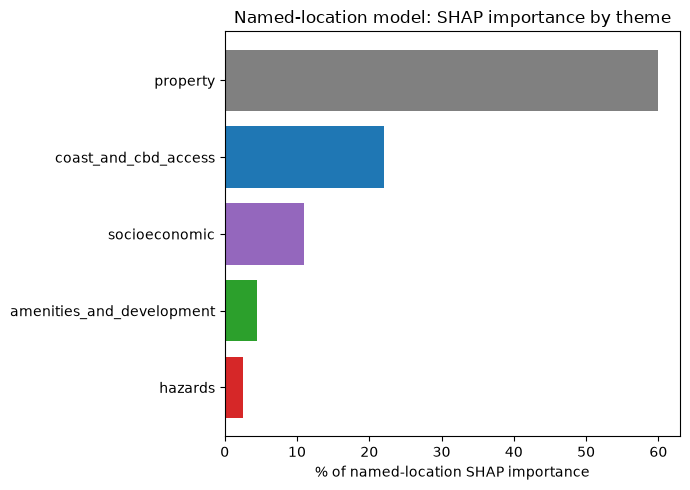

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))
colors_theme = {"socioeconomic": "tab:purple", "coast_and_cbd_access": "tab:blue",
                "hazards": "tab:red", "amenities_and_development": "tab:green"}
ax.barh(theme_share_pct.index[::-1], theme_share_pct.values[::-1],
        color=[colors_theme.get(t, "gray") for t in theme_share_pct.index[::-1]])
ax.set_xlabel("% of named-location SHAP importance")
ax.set_title("Named-location model: SHAP importance by theme")
plt.tight_layout()
plt.show()

## 9. Conclusion

Fill in after running:

- **Headline:** named factors recover **{recovery_pct}** of the value of
  knowing a property's exact coordinates -- the explanation now says
  *coast distance*, *CBD distance*, *deprivation*, *flood risk*, or
  *amenity access*, not an uninterpretable latitude/longitude pair.
- Whichever theme dominates the SHAP breakdown is the actual, nameable
  reason location matters for Auckland prices in this dataset -- state it
  explicitly once the numbers are in.
- This does not contradict `final.ipynb`'s finding that coordinates alone
  are the strongest *single* predictor -- coordinates are a highly
  compressed summary of all of these named factors at once (plus anything
  not captured by them). This notebook asks a complementary question:
  how much of that compression can be *unpacked* into things a person can
  act on.